In [5]:
from matplotlib import pyplot as plt
import cv2
import numpy as np 
from PIL import Image
import pandas as pd
import os, shutil, random
import tensorflow as tf
from tensorflow.keras import layers, callbacks, optimizers
from sklearn.metrics import confusion_matrix, f1_score

In [2]:
!wget "https://cainvas-static.s3.amazonaws.com/media/user_data/cainvas-admin/Road_Crack_DCSV9HG.zip"
! unzip -qo Road_Crack_DCSV9HG.zip

--2026-10-09 08:54:03--  https://cainvas-static.s3.amazonaws.com/media/user_data/cainvas-admin/Road_Crack_DCSV9HG.zip
Resolving cainvas-static.s3.amazonaws.com (cainvas-static.s3.amazonaws.com)... 16.12.36.111, 3.5.213.115, 3.5.209.32, ...
Connecting to cainvas-static.s3.amazonaws.com (cainvas-static.s3.amazonaws.com)|16.12.36.111|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 87484192 (83M) [application/x-zip-compressed]
Saving to: ‘Road_Crack_DCSV9HG.zip’

Road_Crack_DCSV9HG. 100%[===================>]  83.43M  2.44MB/s    in 50s     

2026-10-09 08:54:55 (1.66 MB/s) - ‘Road_Crack_DCSV9HG.zip’ saved [87484192/87484192]



In [6]:
data_dir = 'Road Crack/'
batch_size = 64

image_size = (28,28)

print("Training set")
train_ds = tf.keras.preprocessing.image_dataset_from_directory(data_dir, validation_split=0.2, subset="training", color_mode="grayscale", image_size=image_size, seed=113, shuffle=True, batch_size=batch_size)
print("Validation set")
val_ds = tf.keras.preprocessing.image_dataset_from_directory(data_dir, validation_split=0.2, subset="validation", color_mode="grayscale", image_size=image_size, seed=113, shuffle=True, batch_size=batch_size)
              

Training set
Found 40000 files belonging to 2 classes.
Using 32000 files for training.


I0000 00:00:1791532686.573850   49844 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2145 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Validation set
Found 40000 files belonging to 2 classes.
Using 8000 files for validation.


In [7]:
Xtrain = np.empty((0, *image_size, 1))
ytrain = np.empty((0, 1))

for x in train_ds.enumerate():
    for y in x[1][0]:
        Xtrain = np.append(Xtrain, np.expand_dims(np.array(y), 0), axis=0)
    ytrain = np.append(ytrain, np.array(x[1][1]))
Xtrain.shape , ytrain.shape

((32000, 28, 28, 1), (32000,))

In [8]:
class_names = train_ds.class_names
print(class_names)

['Negative', 'Positive']


In [9]:
Xval = np.empty((0, *image_size, 1))
yval = np.empty((0, 1))

for x in val_ds.enumerate():
    for y in x[1][0]:
        Xval = np.append(Xval, np.expand_dims(np.array(y), 0), axis=0)
    yval = np.append(yval, np.array(x[1][1]))
Xval.shape , yval.shape

((8000, 28, 28, 1), (8000,))

In [10]:
print("Number of samples - ")
for i in range(len(class_names)):
    print(class_names[i], "-", yval.tolist().count(float(i)))

Number of samples - 
Negative - 3999
Positive - 4001


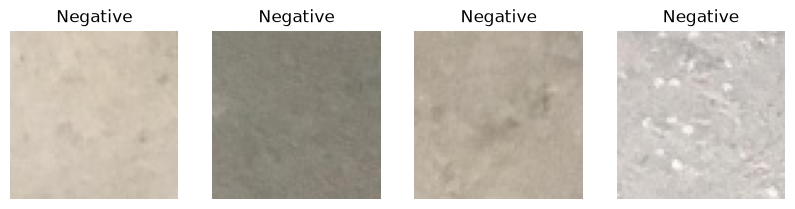

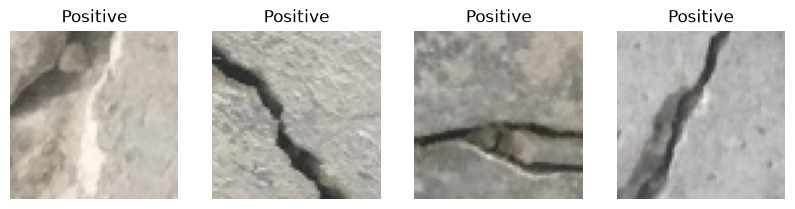

In [11]:
num_samples = 4

for x in class_names:
    plt.figure(figsize=(10,10))
    filenames = os.listdir(data_dir + x)

    for i in range(num_samples):
        ax = plt.subplot(1, num_samples, i+1)
        img = Image.open(os.path.join(data_dir + x, filenames[i]))
        plt.imshow(img)
        plt.title(x)
        plt.axis("off")

In [12]:
Xtrain = Xtrain / 255.0
Xval = Xval / 255.0

model = tf.keras.models.Sequential([
    layers.Conv2D(8, 3, activation='relu', input_shape=Xtrain[0].shape),
    layers.MaxPool2D(pool_size=(2,2)),
    layers.Conv2D(16, 3, activation='relu'),
    layers.MaxPool2D(pool_size=(2,2)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.MaxPool2D(pool_size=(2,2)),
    layers.Flatten(),
    layers.Dense(32, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

cb = [callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)]
model.summary()


/home/ubuntu24/PROJECTS/Road-Crack-Detection-Project/venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,977 (27.25 KB)

 Trainable params: 6,977 (27.25 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(loss=tf.keras.losses.BinaryCrossentropy(), optimizer=tf.keras.optimizers.Adam(0.0001), metrics=['accuracy'])
history = model.fit(Xtrain, ytrain, validation_data=(Xval,yval), epochs=300, callbacks=cb)

W0000 00:00:1791534450.368392   49844 cpu_allocator_impl.cc:82] Allocation of 100352000 exceeds 10% of free system memory.
W0000 00:00:1791534450.560685   49844 cpu_allocator_impl.cc:82] Allocation of 100352000 exceeds 10% of free system memory.


Epoch 1/300


I0000 00:00:1791534456.865648   50360 service.cc:153] XLA service 0x7815f4007b40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1791534456.866300   50360 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.2.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1791534457.022682   50360 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1791534457.906257   50360 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1791534457.953242   50360 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_163886__.34


  72/1000 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5347 - loss: 0.6911

I0000 00:00:1791534465.142842   50360 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1000/1000 ━━━━━━━━━━━━━━━━━━━━ 20s 6ms/step - accuracy: 0.8622 - loss: 0.4609 - val_accuracy: 0.9585 - val_loss: 0.1503
Epoch 2/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9628 - loss: 0.1130 - val_accuracy: 0.9685 - val_loss: 0.0937
Epoch 3/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9689 - loss: 0.0892 - val_accuracy: 0.9719 - val_loss: 0.0833
Epoch 4/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9718 - loss: 0.0822 - val_accuracy: 0.9732 - val_loss: 0.0801
Epoch 5/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9730 - loss: 0.0773 - val_accuracy: 0.9750 - val_loss: 0.0746
Epoch 6/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9748 - loss: 0.0735 - val_accuracy: 0.9761 - val_loss: 0.0715
Epoch 7/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9763 - loss: 0.0709 - val_accuracy: 0.9776 - val_loss: 0.0679
Epoch 8/300
1000/1000 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9773 - loss: 0.0679 - val

250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9921 - loss: 0.0276
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


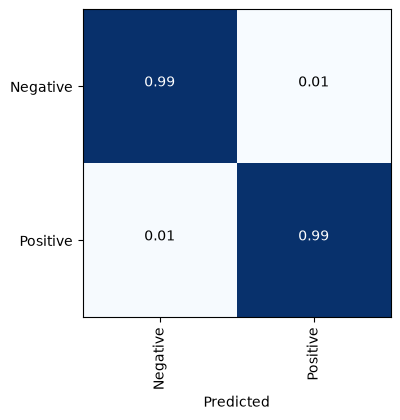

In [21]:
model.evaluate(Xval, yval)
ypred = (model.predict(Xval) > 0.5).astype(int)
cm = confusion_matrix(yval, ypred)
cm = cm.astype('int') / cm.sum(axis=1)[:, np.newaxis]

fig = plt.figure(figsize=(4,4))
ax = fig.add_subplot(111)

for i in range(cm.shape[1]):
    for j in range(cm.shape[0]):
        if cm[i,j] > 0.8:
            clr = "white"
        else:
            clr="black"
        ax.text(j, i, format(cm[i,j], '.2f'), horizontalalignment="center", color = clr)
_ = ax.imshow(cm, cmap=plt.cm.Blues)
ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=90)
ax.set_yticklabels(class_names)
plt.xlabel('Predicted')
plt.ylabel = ('True')
plt.show()

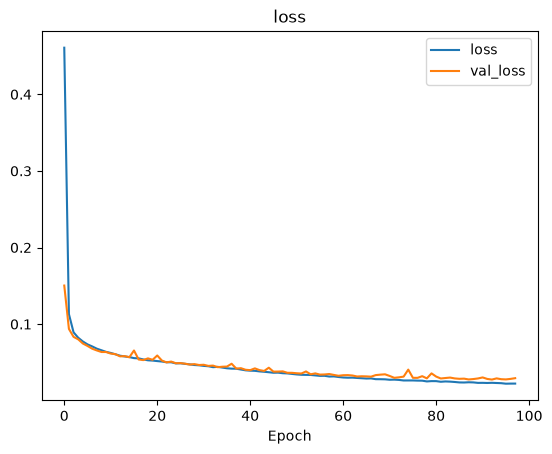

In [24]:
def plot(history, variable1, variable2):
    plt.plot(range(len(history[variable1])), history[variable1])
    plt.plot(range(len(history[variable2])), history[variable2])
    plt.legend([variable1, variable2])
    plt.title(variable1)
    plt.xlabel('Epoch')
    plt.show()

plot(history.history, "loss", "val_loss")

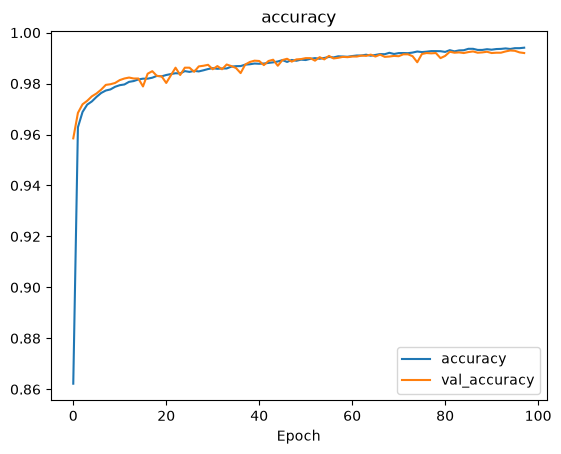

In [25]:
plot(history.history, "accuracy", "val_accuracy")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
Predicted:  Negative ( 0.0 --> 0 )
True Negative


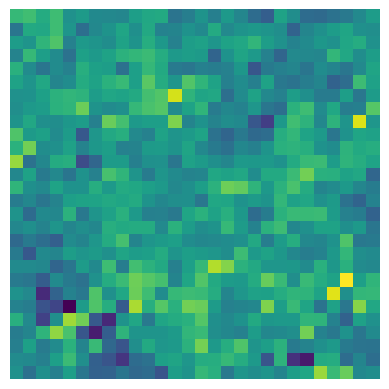

In [26]:
x = random.randint(0, 32 - 1)
for i in val_ds.as_numpy_iterator():
    img, label = i
    plt.axis('off')
    plt.imshow(img[x])
    output = model.predict(np.expand_dims(img[x], 0))[0][0]
    pred = (output > 0.5).astype('int')
    print("Predicted: ", class_names[pred], '(', output, '-->', pred, ')')
    print("True", class_names[label[x]])
    break

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
Predicted:  Negative ( 0.0 --> 0 )
True Negative


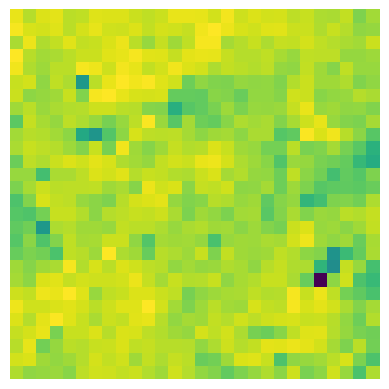

In [27]:
x = random.randint(0,32-1)

for i in val_ds.as_numpy_iterator():
    img, label = i
    plt.axis('off')
    plt.imshow(img[x])
    output = model.predict(np.expand_dims(img[x], 0))[0][0]
    pred = (output > 0.5).astype('int')
    print("Predicted: ", class_names[pred], '(', output, '-->', pred, ')')
    print("True", class_names[label[x]])
    break

In [28]:
model.save("road_crack.h5")